<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/K_means_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means = Finding groups without labels
#### In this file I walk through my first **unsupervised** learning algorithm.

So far every model I built had labels (house price, admitted / not admitted). K-means has **no labels**. I just hand it points and ask: *"find K groups that naturally belong together."*

The algorithm is two repeated steps:
1. **Assign** every point to its closest centroid.
2. **Move** every centroid to the mean of the points assigned to it.

Repeat until nothing changes. I implement it from scratch, then use it to compress an image, then compare with scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## A small 2-D dataset to see it work

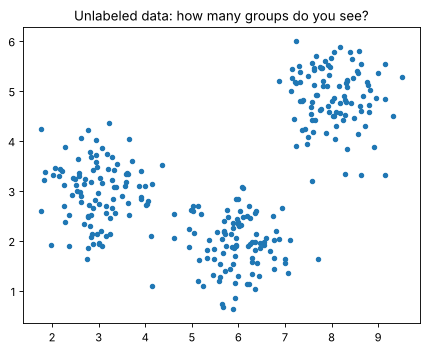

In [2]:
from sklearn.datasets import make_blobs
X, _ = make_blobs(n_samples=300, centers=[[3, 3], [6, 2], [8, 5]], cluster_std=0.6, random_state=7)   # labels thrown away on purpose
plt.scatter(X[:, 0], X[:, 1], s=15); plt.title("Unlabeled data: how many groups do you see?")
plt.show()

## Step 1 - Find the closest centroid for every point
For example $x^{(i)}$ I want $c^{(i)} = \arg\min_j \lVert x^{(i)} - \mu_j \rVert^2$ (index of the nearest centroid). Squared distance is enough - the square root does not change which one is smallest.

In [3]:
def find_closest_centroids(X, centroids):
    idx = np.zeros(X.shape[0], dtype=int)
    for i in range(X.shape[0]):
        distances = [np.sum((X[i] - c) ** 2) for c in centroids]
        idx[i] = np.argmin(distances)
    return idx

initial_centroids = np.array([[3, 3], [6, 2], [8, 5]], dtype=float)
idx = find_closest_centroids(X, initial_centroids)
print("First 5 assignments:", idx[:5])

First 5 assignments: [0 1 2 0 1]


## Step 2 - Move the centroids
New centroid $\mu_k$ = mean of all points currently assigned to cluster $k$.

In [4]:
def compute_centroids(X, idx, K):
    centroids = np.zeros((K, X.shape[1]))
    for k in range(K):
        points = X[idx == k]
        if len(points):                         # guard against an empty cluster
            centroids[k] = points.mean(axis=0)
    return centroids

print(compute_centroids(X, idx, 3).round(2))

[[2.98 2.98]
 [5.96 1.93]
 [8.04 4.87]]


## Put them in a loop

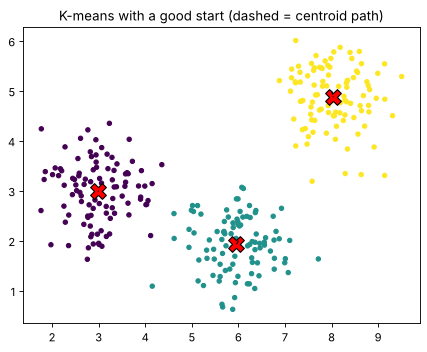

In [5]:
def run_kmeans(X, initial_centroids, max_iters=10):
    centroids = initial_centroids.copy()
    history = [centroids.copy()]
    for _ in range(max_iters):
        idx = find_closest_centroids(X, centroids)
        new = compute_centroids(X, idx, len(centroids))
        history.append(new.copy())
        if np.allclose(new, centroids):         # converged
            break
        centroids = new
    return centroids, idx, history

def plot_clusters(X, idx, centroids, history=None, title=""):
    plt.scatter(X[:, 0], X[:, 1], c=idx, cmap="viridis", s=15)
    if history is not None:
        h = np.array(history)
        for k in range(h.shape[1]):
            plt.plot(h[:, k, 0], h[:, k, 1], "k--", lw=1)
    plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200, c="red", edgecolors="k")
    plt.title(title)

centroids, idx, hist = run_kmeans(X, initial_centroids, max_iters=15)
plot_clusters(X, idx, centroids, hist, "K-means with a good start (dashed = centroid path)")
plt.show()

## Random initialization (and why it matters)
In practice I do not know good starting centroids. The usual method: pick K random training points as the starting centroids. But K-means only finds a **local** optimum, so a bad start can give a bad answer.

The fix: run it many times from different random starts and keep the run with the lowest **distortion cost**

$$J = \frac{1}{m}\sum_{i} \lVert x^{(i)} - \mu_{c^{(i)}} \rVert^2$$

distinct costs found over 30 runs: [0.539 1.322 1.553 1.556 1.614]


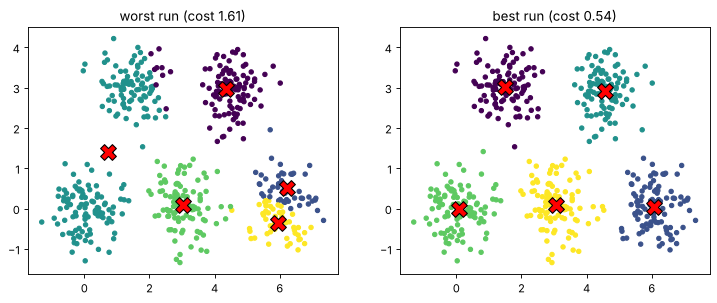

In [6]:
def kmeans_init_centroids(X, K, rng):
    return X[rng.permutation(X.shape[0])[:K]].copy()

def distortion(X, idx, centroids):
    return np.mean(np.sum((X - centroids[idx]) ** 2, axis=1))

# the easy 3-blob data always converges to the same answer, so for this demo I use 5 closer blobs where bad starts really happen
X5, _ = make_blobs(n_samples=500, centers=[[0, 0], [3, 0], [6, 0], [1.5, 3], [4.5, 3]], cluster_std=0.55, random_state=4)
rng = np.random.default_rng(0)
results = []
for run in range(30):
    c0 = kmeans_init_centroids(X5, 5, rng)
    c, i, _ = run_kmeans(X5, c0, max_iters=50)
    results.append((distortion(X5, i, c), c, i))
costs = [r[0] for r in results]
print("distinct costs found over 30 runs:", np.unique(np.round(costs, 3)))
best_cost, best_c, best_i = min(results, key=lambda r: r[0])
worst_cost, worst_c, worst_i = max(results, key=lambda r: r[0])
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); plot_clusters(X5, worst_i, worst_c, title=f"worst run (cost {worst_cost:.2f})")
plt.subplot(1, 2, 2); plot_clusters(X5, best_i, best_c, title=f"best run (cost {best_cost:.2f})")
plt.show()

## Choosing K - the elbow method
More clusters always lowers the cost, so I look for the "elbow" where adding another cluster stops paying off. (Sometimes there is no clear elbow - then I choose K based on what the clusters are *for*.)

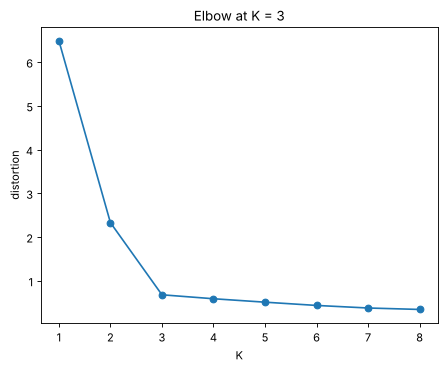

In [7]:
ks = range(1, 9)
elbow = []
for K in ks:
    best = np.inf
    for run in range(5):
        c, i, _ = run_kmeans(X, kmeans_init_centroids(X, K, rng), max_iters=50)
        best = min(best, distortion(X, i, c))
    elbow.append(best)
plt.plot(list(ks), elbow, "o-"); plt.xlabel("K"); plt.ylabel("distortion"); plt.title("Elbow at K = 3")
plt.show()

## Image compression with K-means
An image is just a grid of pixels, each pixel is 3 numbers (R, G, B), and each number takes 256 values -> 24 bits per pixel. 
If I cluster all pixel colors into **K = 16** groups and replace every pixel by its centroid color, I only need to store:
- a 16-color palette (16 x 24 bits), and
- a 4-bit index per pixel.

That is roughly 6x smaller, and the picture still looks like itself.

image shape: (427, 640, 3)
pixel matrix: (273280, 3)


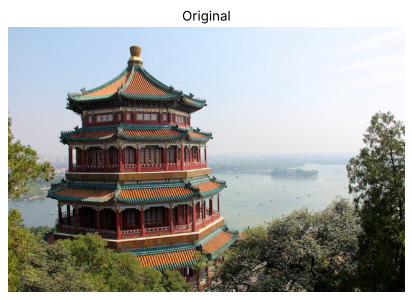

In [8]:
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg") / 255.0                 # (427, 640, 3), values in [0,1]
print("image shape:", img.shape)
X_img = img.reshape(-1, 3)                                    # one row per pixel
print("pixel matrix:", X_img.shape)
plt.imshow(img); plt.axis("off"); plt.title("Original"); plt.show()

compression ratio ~ 6.0x


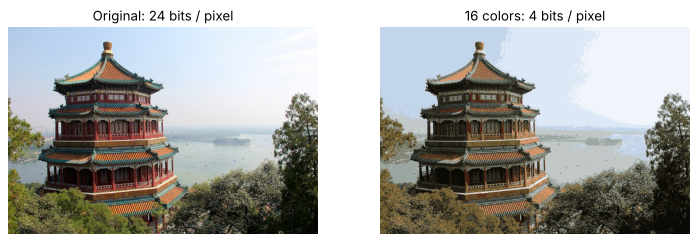

In [9]:
# my NumPy loop is clear but slow on 273k pixels, so I vectorize the assignment step for this part
def find_closest_fast(X, C):
    d = (X ** 2).sum(1, keepdims=True) - 2 * X @ C.T + (C ** 2).sum(1)
    return d.argmin(1)

def run_kmeans_fast(X, K, iters=15, seed=0):
    rng = np.random.default_rng(seed)
    C = X[rng.choice(len(X), K, replace=False)].copy()
    for _ in range(iters):
        idx = find_closest_fast(X, C)
        for k in range(K):
            if (idx == k).any():
                C[k] = X[idx == k].mean(0)
    return C, find_closest_fast(X, C)

K = 16
C, idx_img = run_kmeans_fast(X_img, K)
compressed = C[idx_img].reshape(img.shape)

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.axis("off"); plt.title("Original: 24 bits / pixel")
plt.subplot(1, 2, 2); plt.imshow(compressed); plt.axis("off"); plt.title(f"{K} colors: 4 bits / pixel")
plt.show()
orig_bits = img.shape[0] * img.shape[1] * 24
new_bits = K * 24 + img.shape[0] * img.shape[1] * 4
print(f"compression ratio ~ {orig_bits / new_bits:.1f}x")

## The scikit-learn version

In [10]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)       # n_init = number of random restarts (my loop above)
print("sklearn centroids:\n", np.sort(km.cluster_centers_, axis=0).round(2))
c3, i3, _ = run_kmeans(X, initial_centroids, 50)
print("my centroids:\n", np.sort(c3, axis=0).round(2))
print("sklearn inertia (sum of squares):", round(km.inertia_, 2), "| mine:", round(distortion(X, i3, c3) * len(X), 2))

sklearn centroids:
 [[2.98 1.93]
 [5.96 2.98]
 [8.04 4.87]]
my centroids:
 [[2.98 1.93]
 [5.96 2.98]
 [8.04 4.87]]
sklearn inertia (sum of squares): 204.25 | mine: 204.25


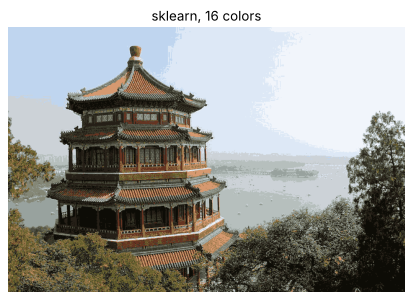

In [11]:
# the same image compression, 3 lines
sample = X_img[np.random.default_rng(0).choice(len(X_img), 20000, replace=False)]    # fit on a sample for speed
km_img = KMeans(n_clusters=16, n_init=3, random_state=0).fit(sample)
compressed_sk = km_img.cluster_centers_[km_img.predict(X_img)].reshape(img.shape)
plt.imshow(compressed_sk); plt.axis("off"); plt.title("sklearn, 16 colors"); plt.show()

## Drawbacks / things to remember
- **I must choose K** up front (elbow / silhouette / domain knowledge).
- **Local optima**: results depend on the random start -> run several and keep the lowest cost (`n_init`).
- **Assumes round, similar-sized clusters** because it uses distance to a mean. Long snakes, rings or very different densities break it (look at DBSCAN or Gaussian mixtures).
- **Sensitive to scale and outliers**: standardize features first, because one big-unit feature dominates the distance.
- It always returns K clusters even if the data has no real structure, so I check whether the clusters mean something.